# Point-Source Contribution — Playground #7

Two players can finish on the *same* points and be completely different assets. One midfielder banks 80% of his haul from goals and assists (matchup-sensitive, boom-or-bust); another grinds out appearances, bonus, and the new **defensive-contribution** points (a near-guaranteed floor). This notebook decomposes each top player's season into **where the points came from**.

Spec: [brainstorming/14](../../brainstorming/14-point-source-contribution.md).

**CS problem:** *additive attribution*. We decompose one scalar (`total_points`) into a fixed set of mutually-exclusive buckets, then normalise each to a **share of the total** — the same shape as a stacked composition (parts that sum to a whole).

**Data source:** the official FPL API. `/api/event/{gw}/live/` returns, for every player-GW, an `explain` block — FPL's *own* per-fixture point breakdown, tagging each slice with an identifier (`goals_scored`, `clean_sheets`, `defensive_contribution`, …) and the exact points it contributed. We map those identifiers onto our buckets and sum. `/api/bootstrap-static/` supplies name, position, and team.

**Why this is lossless by construction:** we aren't re-deriving the scoring rules and hoping they reconcile — we're reading FPL's authoritative attribution directly. The per-GW slices sum back to `total_points` exactly, so every share below is auditable, not approximate. Deductions arrive already-signed (negative) from the API.

## Config — edit me

In [29]:
SEASON = "2026-27"   # display label only — the API always serves the current season
API    = "https://fantasy.premierleague.com/api"
BOOTSTRAP_URL = f"{API}/bootstrap-static/"
LIVE_URL      = API + "/event/{gw}/live/"

# Analysis universe: top-K per position by TOTAL points. K/L/M/N here.
TOP_PER_POS = {"GK": 8, "DEF": 17, "MID": 15, "FWD": 6}   # 32 players

# --- Sample-size guards (the season is young: a few GWs of data swing shares hard) ---
EXCLUDE_PROVISIONAL = True   # drop the in-progress GW (bonus not final until FPL closes it)
LAST_N_GW   = None           # e.g. 5 = only the last 5 GWs; None = whole season
MIN_MINUTES = 300            # universe floor: skip rotation players with fewer minutes
RANK_BY     = "total_points" # or "pts_per90" to rank the top-K on a per-90 basis

# --- Point buckets ---
BUCKETS = ["appearance", "goals", "assists", "clean_sheets", "def_contrib", "gk_pts", "bonus", "deductions"]

# FPL's `explain` block tags each point slice with an identifier. We map those
# identifiers onto our buckets and sum the points FPL already assigned. No
# scoring rules to re-derive: deductions come through already-signed (negative).
IDENT_TO_BUCKET = {
    "minutes":                "appearance",
    "goals_scored":           "goals",
    "assists":                "assists",
    "clean_sheets":           "clean_sheets",
    "defensive_contribution": "def_contrib",
    "saves":                  "gk_pts",
    "penalties_saved":        "gk_pts",
    "bonus":                  "bonus",
    "goals_conceded":         "deductions",
    "own_goals":              "deductions",
    "penalties_missed":       "deductions",
    "yellow_cards":           "deductions",
    "red_cards":              "deductions",
}

## Fetch — bootstrap metadata + live data for every finished GW *and* the current in-progress GW

Points from the in-progress GW are **provisional** (flagged with a `provisional` column): bonus and appearance points aren't final until FPL marks the GW finished. The reconciliation below still holds — FPL's `explain` slices sum to the live `total_points` regardless.

In [30]:
import urllib.request, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def get_json(url):
    req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
    return json.load(urllib.request.urlopen(req, timeout=60))

# --- metadata: element id -> name / position / team ---
boot = get_json(BOOTSTRAP_URL)
POS_MAP    = {1: "GK", 2: "DEF", 3: "MID", 4: "FWD"}
team_name  = {t["id"]: t["name"] for t in boot["teams"]}
meta = {e["id"]: (f'{e["first_name"]} {e["second_name"]}'.strip(),
                  POS_MAP[e["element_type"]],
                  team_name[e["team"]]) for e in boot["elements"]}

# --- which gameweeks to pull ---
# Finished GWs are settled. We also pull the current *in-progress* GW (started
# but not yet finished) so the season-to-date split reflects live fixtures.
# Its points are provisional — bonus isn't final until FPL marks the GW finished.
finished    = [ev["id"] for ev in boot["events"] if ev["finished"]]
in_progress = [ev["id"] for ev in boot["events"]
               if ev.get("is_current") and not ev["finished"]]
to_fetch    = sorted(set(finished) | set(in_progress))

rows = []
for gw_id in to_fetch:
    live = get_json(LIVE_URL.format(gw=gw_id))
    for el in live["elements"]:
        st = el["stats"]
        name, position, team = meta[el["id"]]
        row = {"name": name, "position": position, "team": team, "round": gw_id,
               "provisional": gw_id in in_progress,
               "minutes": st["minutes"], "total_points": st["total_points"]}
        for b in BUCKETS:
            row[b] = 0.0
        # `explain` is per-fixture (a list) — a double GW has >1 entry, so we sum.
        for fixture in el["explain"]:
            for s in fixture["stats"]:
                bucket = IDENT_TO_BUCKET.get(s["identifier"])
                if bucket is not None:
                    row[bucket] += s["points"]
        rows.append(row)

gw = pd.DataFrame(rows)
prov = f" + GW{in_progress} in progress" if in_progress else ""
print(f"{len(gw):,} player-GW rows | {gw['name'].nunique()} players | "
      f"GWs {gw['round'].min()}–{gw['round'].max()} "
      f"({len(finished)} finished{prov})")

5,220 player-GW rows | 669 players | GWs 1–8 (7 finished + GW[8] in progress)


## Reconcile — do FPL's own slices sum back to `total_points`?

Each bucket is already the sum of FPL's authoritative per-fixture point slices (`explain`). This isn't a re-derivation, so the check is a *sanity guard*: our bucket total should equal the recorded `total_points` for every player-GW. Any non-zero residual would mean an `explain` identifier we haven't mapped — surface it before trusting the split.

In [31]:
gw["recon"] = gw[BUCKETS].sum(axis=1)
gw["resid"] = gw["total_points"] - gw["recon"]

bad = int((gw["resid"] != 0).sum())
print(f"reconciliation: {bad} / {len(gw):,} rows with non-zero residual | "
      f"abs residual sum = {gw['resid'].abs().sum():.0f} of {gw['total_points'].sum():,.0f} total pts")
assert bad == 0, "an explain identifier is unmapped — extend IDENT_TO_BUCKET before trusting the split"
print("✓ every player-GW's buckets sum to its total_points — the decomposition is lossless")

reconciliation: 0 / 5,220 rows with non-zero residual | abs residual sum = 0 of 7,351 total pts
✓ every player-GW's buckets sum to its total_points — the decomposition is lossless


## Aggregate to season totals per player

In [32]:
# Apply the sample guards before aggregating.
gw_use = gw.copy()
if EXCLUDE_PROVISIONAL:
    gw_use = gw_use[~gw_use["provisional"]]
if LAST_N_GW:
    gw_use = gw_use[gw_use["round"] > gw_use["round"].max() - LAST_N_GW]
print(f"using GWs {gw_use['round'].min()}–{gw_use['round'].max()} "
      f"({gw_use['round'].nunique()} GWs, {len(gw_use):,} rows)")

agg = {b: "sum" for b in BUCKETS}
agg.update({"total_points": "sum", "minutes": "sum", "position": "first"})
season = gw_use.groupby("name").agg(agg).reset_index()

# Team label: most-frequent team across the player's GW rows.
team_of = gw_use.groupby("name")["team"].agg(lambda s: s.mode().iloc[0])
season["team"] = season["name"].map(team_of)

# Per-90 basis: removes the minutes advantage so part-time players compare fairly.
season["pts_per90"] = (season["total_points"] / season["minutes"].clip(lower=1) * 90).round(2)

season = season[(season["total_points"] > 0) & (season["minutes"] >= MIN_MINUTES)].copy()
print(f"{len(season)} players with a positive total and >= {MIN_MINUTES} minutes")
season.sort_values(RANK_BY, ascending=False).head()

using GWs 1–7 (7 GWs, 4,551 rows)
220 players with a positive total and >= 300 minutes


,name,appearance,goals,assists,clean_sheets,def_contrib,gk_pts,bonus,deductions,total_points,minutes,position,team,pts_per90
460,Maxim De Cuyper,14.0,12.0,9.0,20.0,0.0,0.0,8.0,-4.0,59,580,DEF,Brighton,9.16
187,Erling Haaland,14.0,32.0,0.0,0.0,0.0,0.0,12.0,0.0,58,619,FWD,Man City,8.43
525,Pascal Groß,14.0,15.0,18.0,5.0,0.0,0.0,9.0,-3.0,58,610,MID,Brighton,8.56
405,Luka Vušković,14.0,6.0,3.0,20.0,8.0,0.0,2.0,-2.0,51,617,DEF,Brighton,7.44
333,João Pedro Junqueira de Jesus,12.0,20.0,9.0,0.0,0.0,0.0,9.0,-3.0,47,521,FWD,Chelsea,8.12


## Select the universe — top-K per position

Ranked by `RANK_BY` (total points or points per 90) among players above `MIN_MINUTES`.

In [33]:
picks = []
for p, k in TOP_PER_POS.items():
    picks.append(season[season["position"] == p]
                 .sort_values(RANK_BY, ascending=False)
                 .head(k))
uni = pd.concat(picks, ignore_index=True)
order = {"GK": 0, "DEF": 1, "MID": 2, "FWD": 3}
uni = uni.sort_values(["position", "total_points"],
                      key=lambda s: s.map(order) if s.name == "position" else s,
                      ascending=[True, False]).reset_index(drop=True)
print(f"{len(uni)} players:",
      ", ".join(f"{p}×{TOP_PER_POS[p]}" for p in ["GK", "DEF", "MID", "FWD"]))
uni[["name", "position", "team", "total_points", "pts_per90", "minutes"]]

46 players: GK×8, DEF×17, MID×15, FWD×6


,name,position,team,total_points,pts_per90,minutes
0,David Raya Martín,GK,Arsenal,42,6.00,630
1,Konstantinos Tzolakis,GK,Hull City,39,5.57,630
2,Bart Verbruggen,GK,Brighton,38,5.43,630
3,James Trafford,GK,Leeds,32,4.57,630
4,Alisson Becker,GK,Liverpool,30,4.29,630
5,Gianluigi Donnarumma,GK,Man City,29,4.14,630
6,Jordan Pickford,GK,Everton,28,4.00,630
7,Bernd Leno,GK,Fulham,26,3.71,630
8,Maxim De Cuyper,DEF,Brighton,59,9.16,580
9,Luka Vušković,DEF,Brighton,51,7.44,617


## Contribution table

Two normalisations, on purpose:
- **Positive-share columns** (`%goals … %bonus`) divide each positive bucket by **gross positive points** (all buckets except deductions), so they sum to ~100% and drive the clean stacked bar below.
- **`%deductions`** is reported separately as a share of gross positive — it's a *drag* on the total, not a slice of it, so folding it into the stack would be dishonest.

In [34]:
POS_BUCKETS = ["appearance", "goals", "assists", "clean_sheets", "def_contrib", "gk_pts", "bonus"]
uni["gross_pos"] = uni[POS_BUCKETS].sum(axis=1)

tab = uni[["name", "position", "team", "total_points", "pts_per90"]].copy()
for b in POS_BUCKETS:
    tab[f"%{b}"] = (uni[b] / uni["gross_pos"] * 100).round(1)
tab["%deductions"] = (uni["deductions"] / uni["gross_pos"] * 100).round(1)

pretty = tab.rename(columns={
    "total_points": "pts", "pts_per90": "pts/90", "%appearance": "%appear", "%clean_sheets": "%CS",
    "%def_contrib": "%DC", "%gk_pts": "%GKpts", "%deductions": "%deduct"})
pretty

,name,position,team,pts,pts/90,%appear,%goals,%assists,%CS,%DC,%GKpts,%bonus,%deduct
0,David Raya Martín,GK,Arsenal,42,6.00,32.6,0.0,0.0,37.2,0.0,16.3,14.0,-2.3
1,Konstantinos Tzolakis,GK,Hull City,39,5.57,32.6,0.0,0.0,27.9,0.0,25.6,14.0,-9.3
2,Bart Verbruggen,GK,Brighton,38,5.43,35.0,0.0,0.0,50.0,0.0,10.0,5.0,-5.0
3,James Trafford,GK,Leeds,32,4.57,42.4,0.0,0.0,24.2,0.0,18.2,15.2,-3.0
4,Alisson Becker,GK,Liverpool,30,4.29,41.2,0.0,0.0,35.3,0.0,8.8,14.7,-11.8
5,Gianluigi Donnarumma,GK,Man City,29,4.14,42.4,0.0,0.0,36.4,0.0,18.2,3.0,-12.1
6,Jordan Pickford,GK,Everton,28,4.00,45.2,0.0,0.0,38.7,0.0,12.9,3.2,-9.7
7,Bernd Leno,GK,Fulham,26,3.71,48.3,0.0,0.0,27.6,0.0,17.2,6.9,-10.3
8,Maxim De Cuyper,DEF,Brighton,59,9.16,22.2,19.0,14.3,31.7,0.0,0.0,12.7,-6.3
9,Luka Vušković,DEF,Brighton,51,7.44,26.4,11.3,5.7,37.7,15.1,0.0,3.8,-3.8


## Money shot — 100% stacked contribution bars

One horizontal bar per player, grouped by position and ordered by total points. Read left-to-right: *what kind of scorer is this?*

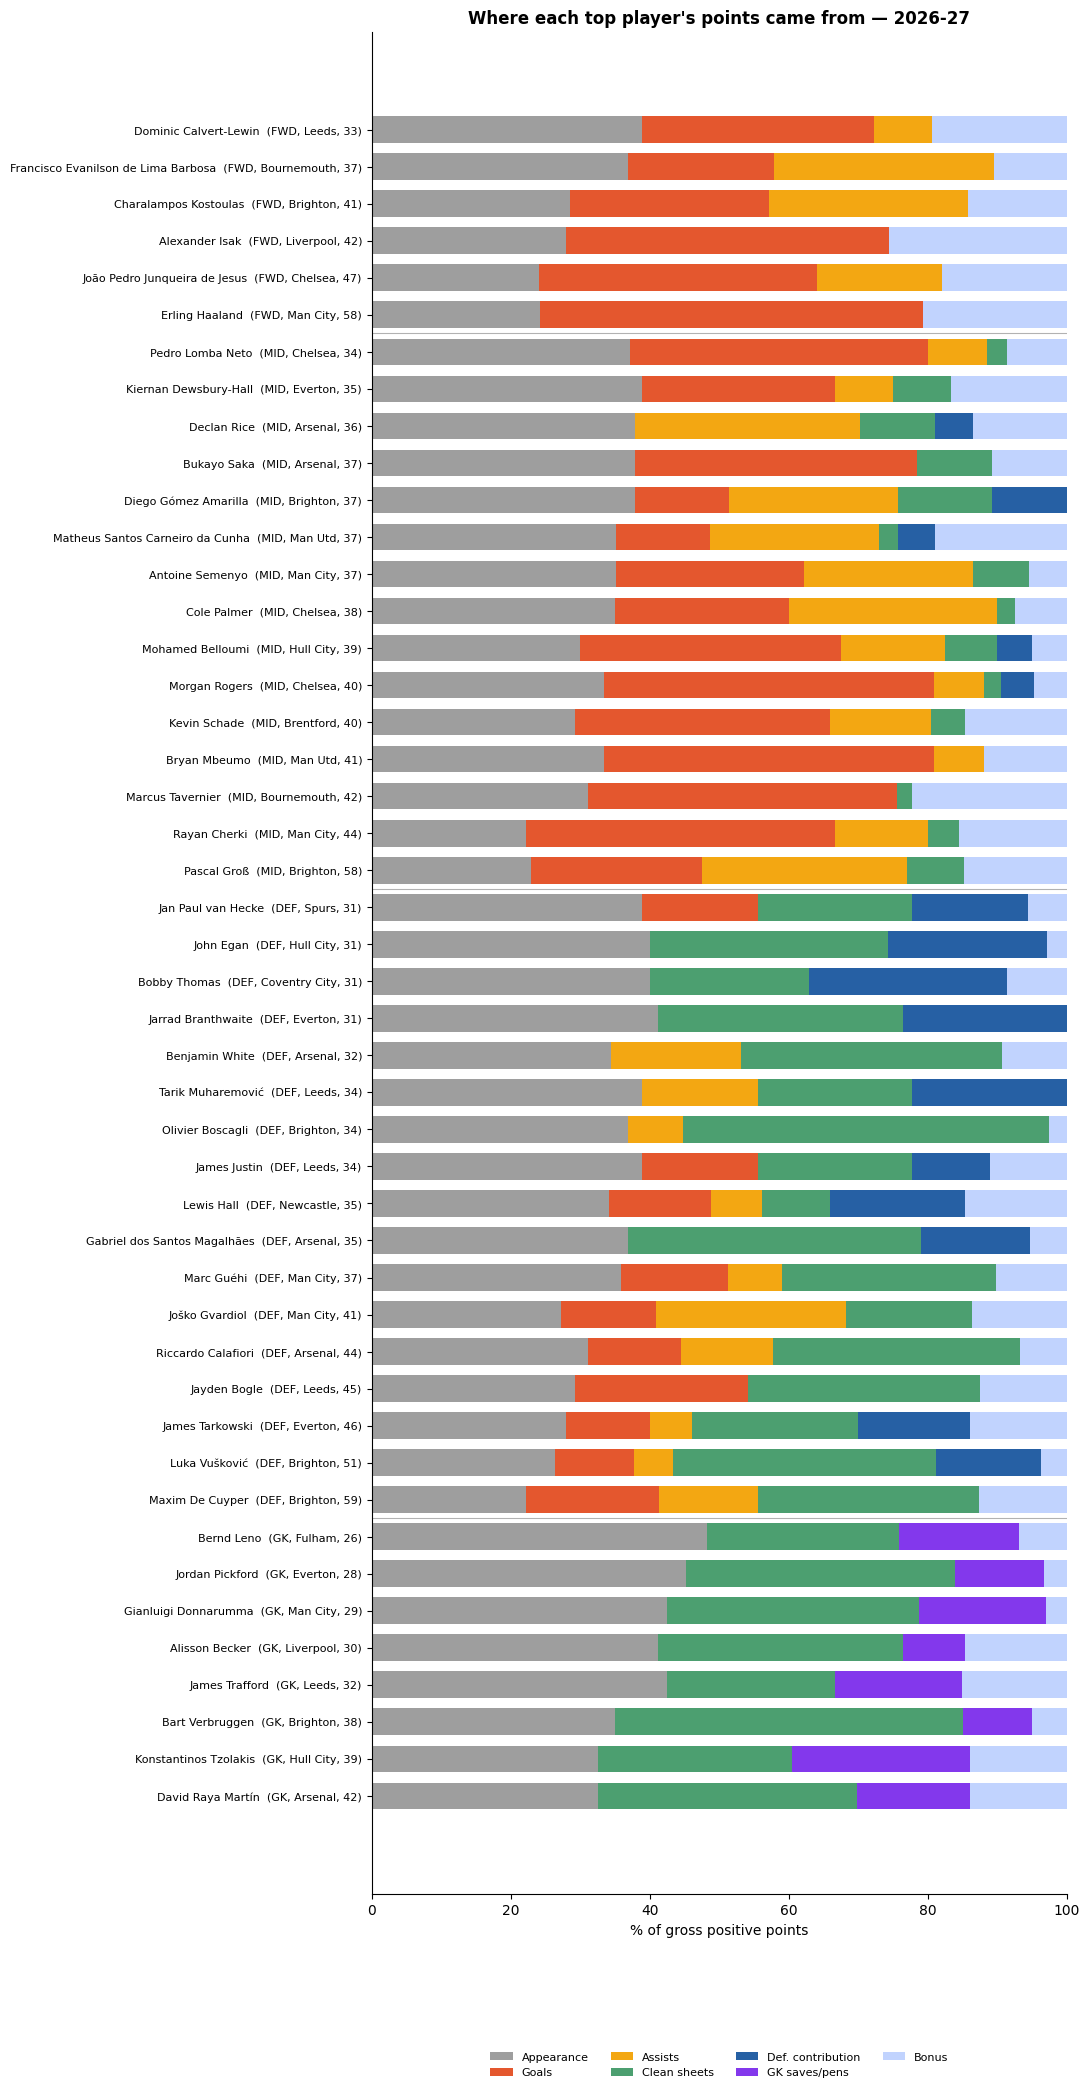

In [35]:
COLORS = {
    "appearance": "#9e9e9e", "goals": "#e4572e", "assists": "#f3a712",
    "clean_sheets": "#4c9f70", "def_contrib": "#2660a4", "gk_pts": "#8338ec",
    "bonus": "#c1d3fe"}
LABELS = {"appearance": "Appearance", "goals": "Goals", "assists": "Assists",
          "clean_sheets": "Clean sheets", "def_contrib": "Def. contribution",
          "gk_pts": "GK saves/pens", "bonus": "Bonus"}

d = uni.copy()
shares = d[POS_BUCKETS].div(d["gross_pos"], axis=0) * 100
y = np.arange(len(d))[::-1]   # top of chart = first row

fig, ax = plt.subplots(figsize=(11, 0.42 * len(d) + 1.5))
left = np.zeros(len(d))
for b in POS_BUCKETS:
    ax.barh(y, shares[b], left=left, color=COLORS[b], label=LABELS[b], height=0.72)
    left += shares[b].values

ax.set_yticks(y)
ax.set_yticklabels([f"{n}  ({p}, {t}, {int(pt)})"
                    for n, p, t, pt in zip(d["name"], d["position"], d["team"], d["total_points"])],
                   fontsize=8)
ax.set_xlim(0, 100); ax.set_xlabel("% of gross positive points")
ax.set_title(f"Where each top player's points came from — {SEASON}", fontsize=12, weight="bold")

# position dividers
bounds = np.cumsum([TOP_PER_POS[p] for p in ["GK", "DEF", "MID", "FWD"]])[:-1]
for b in bounds:
    ax.axhline(len(d) - b - 0.5, color="black", lw=0.8, alpha=0.3)

ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.06 - 0.9/len(d)), fontsize=8, frameon=False)
ax.invert_yaxis(); ax.set_yticks(y); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

## Heatmap — the same shares as a grid

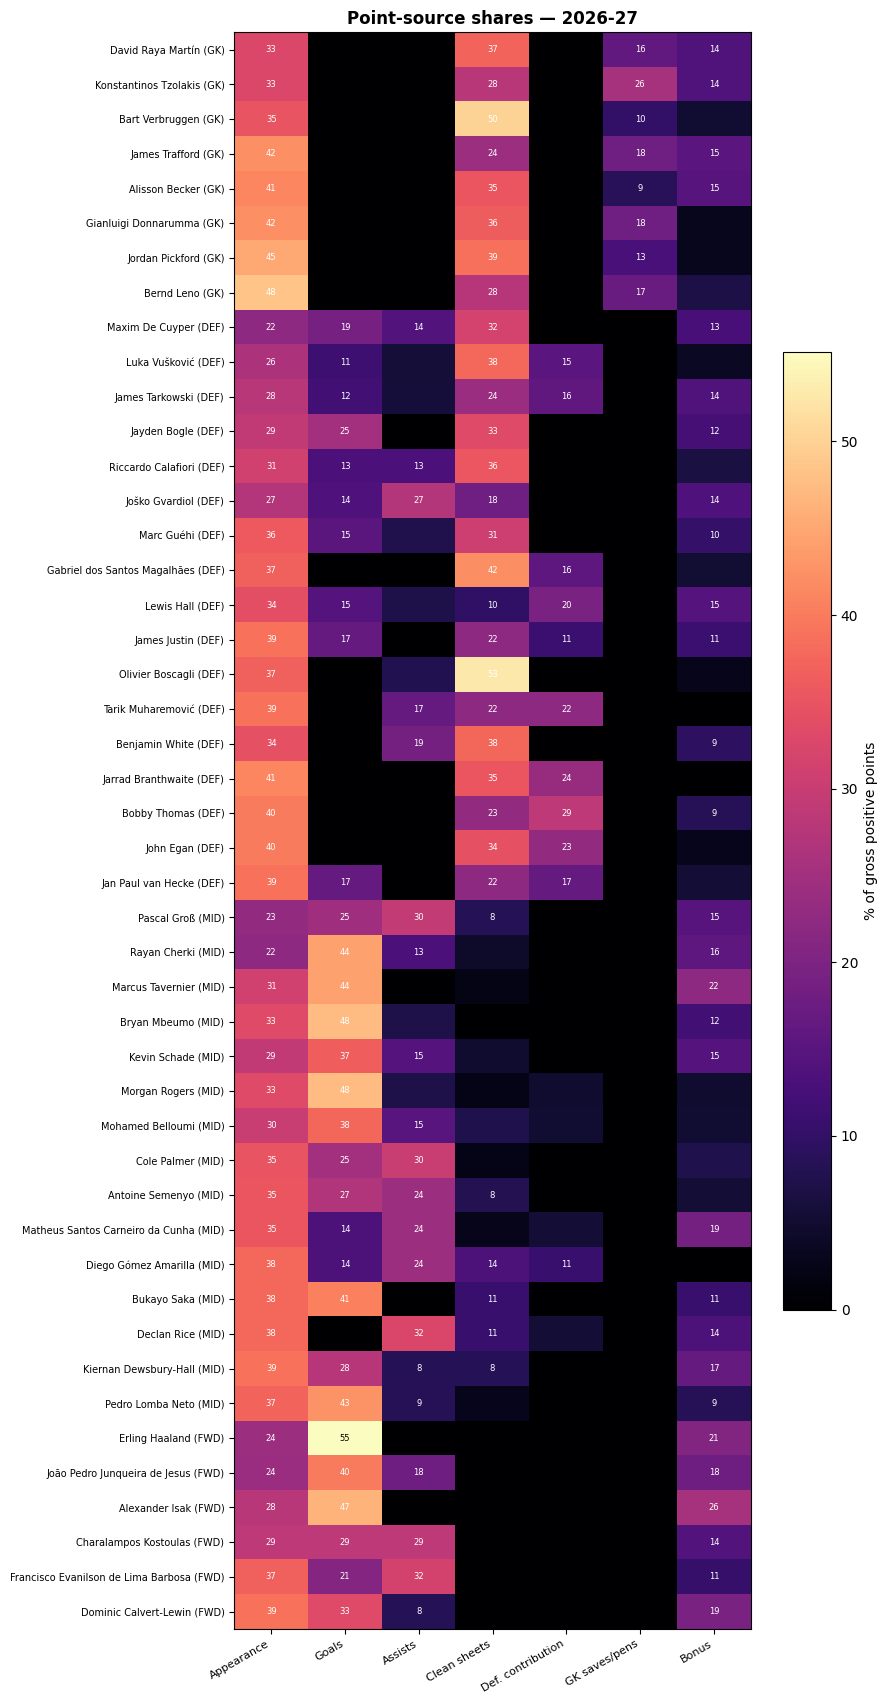

In [36]:
fig, ax = plt.subplots(figsize=(9, 0.34 * len(d) + 1.5))
M = shares[POS_BUCKETS].values
im = ax.imshow(M, aspect="auto", cmap="magma")
ax.set_xticks(range(len(POS_BUCKETS)))
ax.set_xticklabels([LABELS[b] for b in POS_BUCKETS], rotation=30, ha="right", fontsize=8)
ax.set_yticks(range(len(d)))
ax.set_yticklabels([f"{n} ({p})" for n, p in zip(d["name"], d["position"])], fontsize=7)
for i in range(len(d)):
    for j in range(len(POS_BUCKETS)):
        if M[i, j] >= 8:
            ax.text(j, i, f"{M[i, j]:.0f}", ha="center", va="center",
                    color="white" if M[i, j] < 55 else "black", fontsize=6)
fig.colorbar(im, ax=ax, label="% of gross positive points", shrink=0.6)
ax.set_title(f"Point-source shares — {SEASON}", fontsize=12, weight="bold")
plt.tight_layout(); plt.show()

## Explosive vs grinder — attacking share vs personal-floor share

- **Attacking share** = goals + assists (matchup-sensitive, boom-or-bust).
- **Personal floor** = appearance + defensive contribution — points a player banks through his own involvement.
- **Clean sheets are deliberately excluded**: they depend on the *team*, not the player, so they are not a guaranteed floor. They stay visible in the stacked bars above.

Dashed lines mark the median of each axis; top-left = grinders, bottom-right = explosive attackers. Bubble area is proportional to total points. This is the bridge to [#05 Fixture-Proof Players](../05-fixture-proof/).

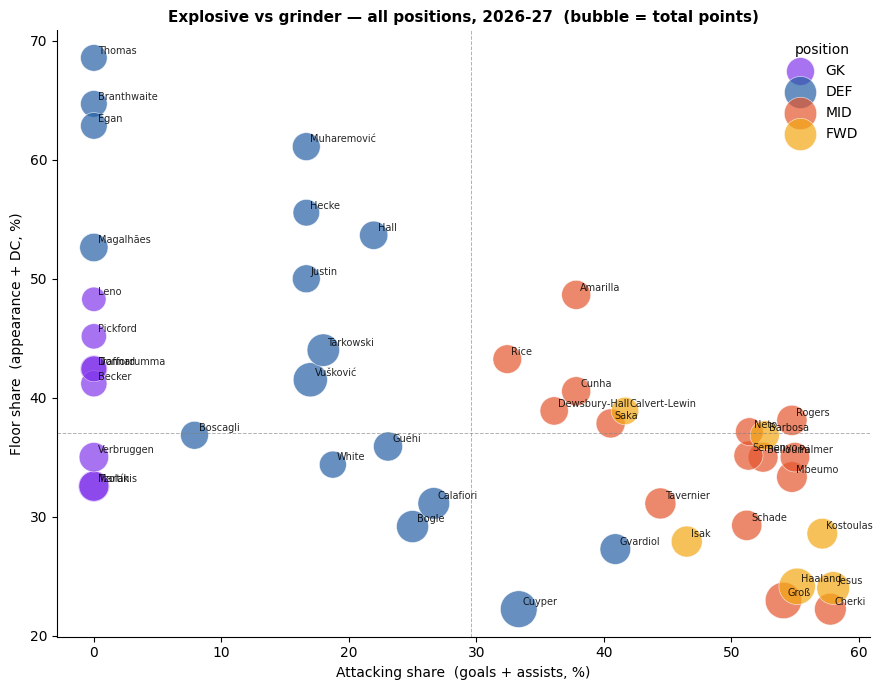

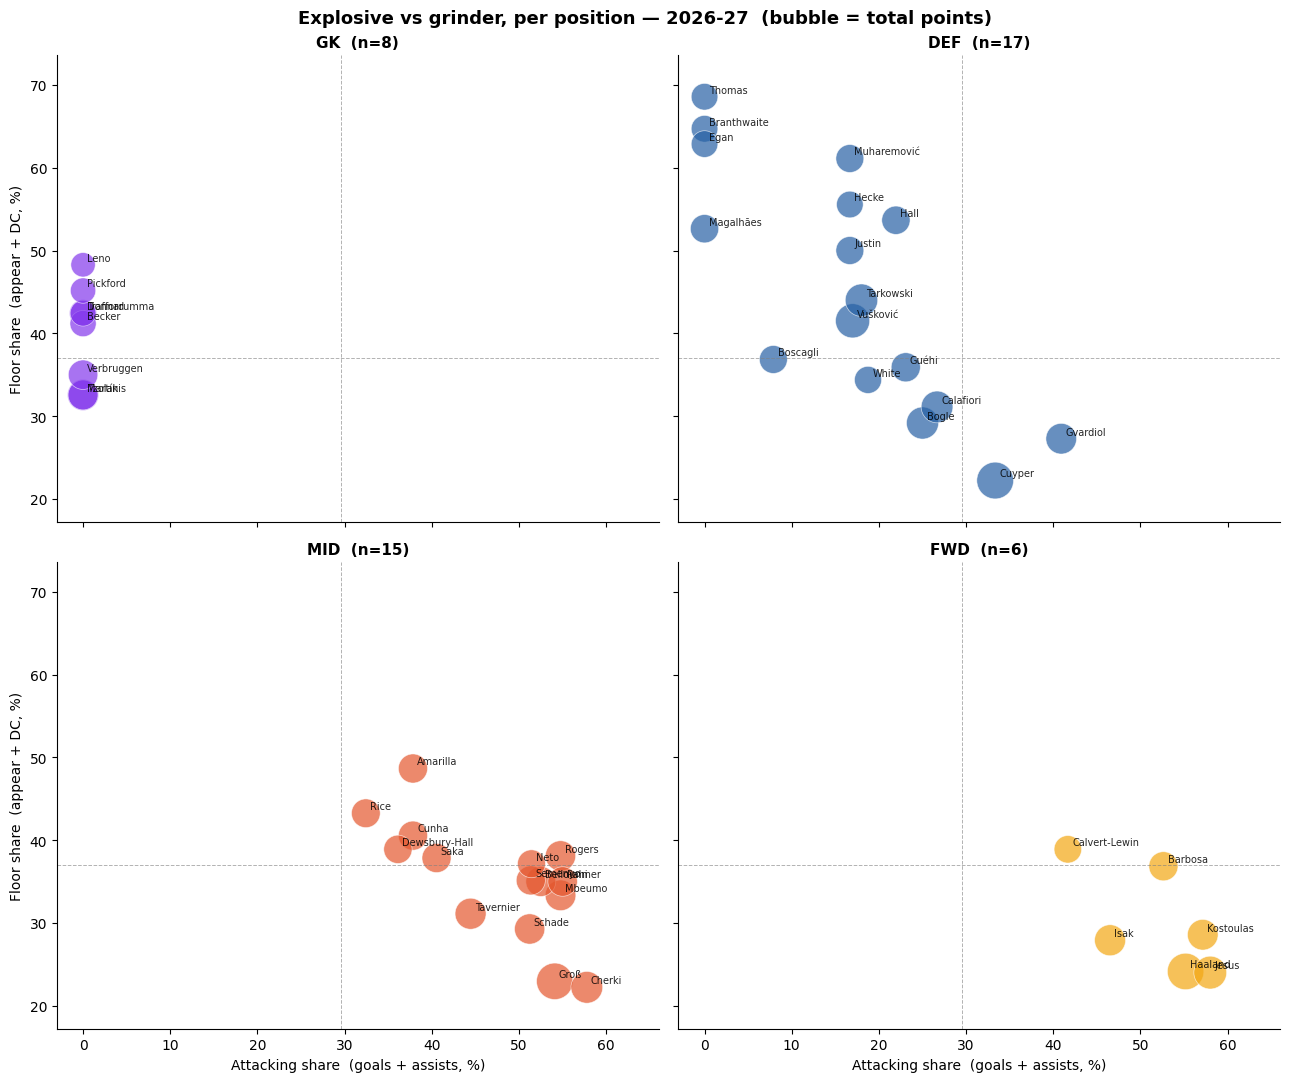

In [37]:
d["attack_share"] = shares["goals"] + shares["assists"]
d["floor_share"] = shares["appearance"] + shares["def_contrib"]
POS_COLOR = {"GK": "#8338ec", "DEF": "#2660a4", "MID": "#e4572e", "FWD": "#f3a712"}
POS_ORDER = ["GK", "DEF", "MID", "FWD"]

SIZE_MAX = 700
d["bubble"] = d["total_points"] / d["total_points"].max() * SIZE_MAX

def scatter(ax, sub, title, annotate_all=True):
    for p in POS_ORDER:
        s = sub[sub["position"] == p]
        if len(s):
            ax.scatter(s["attack_share"], s["floor_share"], s=s["bubble"],
                       color=POS_COLOR[p], alpha=0.7, label=p, edgecolor="white", linewidth=0.5)
    for _, r in sub.iterrows():
        ax.annotate(r["name"].split()[-1], (r["attack_share"], r["floor_share"]),
                    fontsize=7, alpha=0.85, xytext=(3, 3), textcoords="offset points")
    ax.axvline(d["attack_share"].median(), color="grey", ls="--", lw=0.7, alpha=0.6)
    ax.axhline(d["floor_share"].median(), color="grey", ls="--", lw=0.7, alpha=0.6)
    ax.set_title(title, fontsize=11, weight="bold")
    ax.spines[["top", "right"]].set_visible(False)

# --- 1) All positions together (the overview) ---
fig, ax = plt.subplots(figsize=(9, 7))
scatter(ax, d, f"Explosive vs grinder — all positions, {SEASON}  (bubble = total points)")
ax.set_xlabel("Attacking share  (goals + assists, %)")
ax.set_ylabel("Floor share  (appearance + DC, %)")
ax.legend(title="position", frameon=False)
plt.tight_layout(); plt.show()

# --- 2) One panel per position (room for every name), shared axes for comparability ---
xlim = (-3, d["attack_share"].max() + 8)
ylim = (d["floor_share"].min() - 5, d["floor_share"].max() + 5)
fig, axes = plt.subplots(2, 2, figsize=(13, 11), sharex=True, sharey=True)
for ax, p in zip(axes.ravel(), POS_ORDER):
    sub = d[d["position"] == p]
    scatter(ax, sub, f"{p}  (n={len(sub)})")
    ax.set_xlim(*xlim); ax.set_ylim(*ylim)
    if ax in axes[:, 0]:
        ax.set_ylabel("Floor share  (appear + DC, %)")
    if ax in axes[-1, :]:
        ax.set_xlabel("Attacking share  (goals + assists, %)")
fig.suptitle(f"Explosive vs grinder, per position — {SEASON}  (bubble = total points)",
             fontsize=13, weight="bold")
plt.tight_layout(); plt.show()

## Repeatable or one big haul? — gameweek stack for the top 10

Points per GW, stacked by source, for the ten highest scorers in the universe. A tall single bar with the rest thin means the share came from one haul; an even run means a repeatable source. Deductions plot below zero.

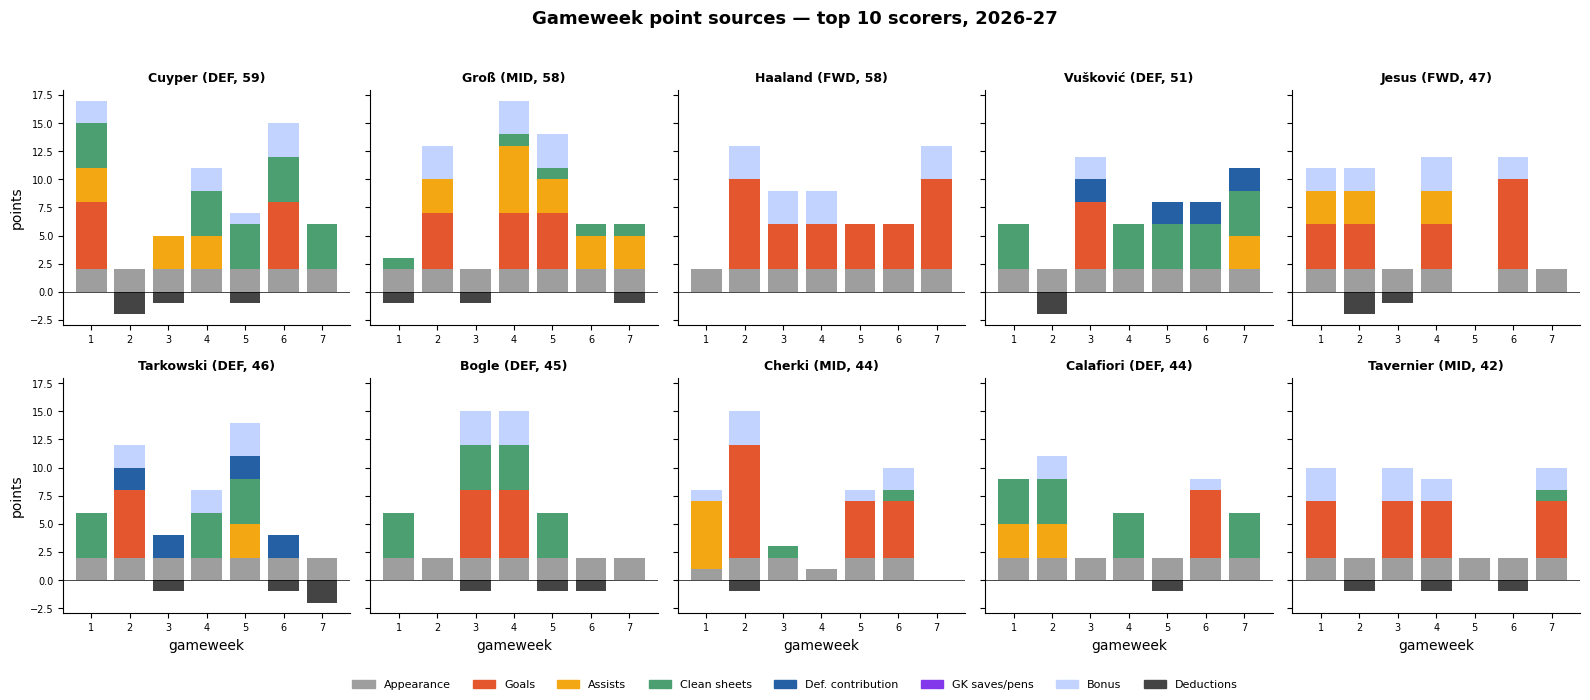

In [38]:
top10 = uni.sort_values("total_points", ascending=False).head(10)["name"].tolist()
rounds = sorted(gw_use["round"].unique())
STACK = POS_BUCKETS  # positives stack up, deductions plot below zero

fig, axes = plt.subplots(2, 5, figsize=(16, 7), sharey=True)
for ax, name in zip(axes.ravel(), top10):
    g = gw_use[gw_use["name"] == name].groupby("round")[BUCKETS].sum().reindex(rounds, fill_value=0)
    pos_bottom = np.zeros(len(rounds))
    for b in STACK:
        ax.bar(rounds, g[b], bottom=pos_bottom, color=COLORS[b], width=0.8)
        pos_bottom += g[b].values
    ax.bar(rounds, g["deductions"], color="#444444", width=0.8)
    ax.axhline(0, color="black", lw=0.5)
    pos = uni.loc[uni["name"] == name, "position"].iloc[0]
    ax.set_title(f"{name.split()[-1]} ({pos}, {int(uni.loc[uni['name'] == name, 'total_points'].iloc[0])})", fontsize=9, weight="bold")
    ax.set_xticks(rounds); ax.tick_params(labelsize=7)
    ax.spines[["top", "right"]].set_visible(False)
for ax in axes[:, 0]:
    ax.set_ylabel("points")
for ax in axes[-1, :]:
    ax.set_xlabel("gameweek")
handles = [plt.Rectangle((0, 0), 1, 1, color=COLORS[b]) for b in STACK] + [plt.Rectangle((0, 0), 1, 1, color="#444444")]
fig.legend(handles, [LABELS[b] for b in STACK] + ["Deductions"], ncol=8, loc="lower center", fontsize=8, frameon=False)
fig.suptitle(f"Gameweek point sources — top 10 scorers, {SEASON}", fontsize=13, weight="bold")
plt.tight_layout(rect=(0, 0.04, 1, 0.96)); plt.show()

## Takeaways

- **The decomposition is lossless.** Every player-GW's buckets sum to its exact `total_points` — because we read FPL's *own* per-fixture attribution (`explain`) straight from the API, not a re-derivation of the scoring rules. Every share below is auditable, not approximate.
- **Same total, different asset.** The stacked bars separate boom-or-bust attackers (attacking share dominant) from grinders whose floor is appearance + bonus + the new defensive-contribution points.
- **Defensive contribution is a real, new slice** — its size per player is the first clean read on who actually banks those points.
- **Bridge to #05:** high floor-share players are the natural fixture-proof candidates; the explosive/grinder scatter is where to start that cross-read.

*Read the table + money shot together: totals tell you the hook, the split tells you how repeatable it is.*